<a href="https://colab.research.google.com/github/zunairazunaira242006-del/mvj-data-analytics-internship-2026/blob/main/Day_19_BBMP_Clustering_and_Rainfall_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/day-19 dataset.csv')

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (199, 29)
   Ward_No                 Ward Name BBMP Zone Name  \
0      1.0           Kempegowda Ward      Yelahanka   
1      2.0          Chowdeswari Ward      Yelahanka   
2      3.0                    Atturu      Yelahanka   
3      4.0  Yelahanka Satellite Town      Yelahanka   
4      5.0                   Jakkuru      Yelahanka   

  Assembly Constituency Name  MP Constituency Population (2011)  Area (sq km)  \
0                  Yelahanka     Chikballapur             34783          10.9   
1                  Yelahanka     Chikballapur             36602           6.5   
2                  Yelahanka     Chikballapur             58129           8.8   
3                  Yelahanka     Chikballapur             41986           4.6   
4            Byatarayanapura  Bangalore North             52025          23.5   

  Households # (Census 2011) Road Length (kms)  Lakes #  ... BMTC TTMC #  \
0                       8647                86        2  ...           0   
1    

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Missing Values:
Ward_No                                         1
Ward Name                                       0
BBMP Zone Name                                  1
Assembly Constituency Name                      1
MP Constituency                                 1
Population (2011)                               0
Area (sq km)                                    0
Households # (Census 2011)                      0
Road Length (kms)                               0
Lakes #                                         0
Lake area (sq m)                                0
Parks #                                         0
Park area (sq m)                                0
Playgrounds #                                   0
Playground area (sq m)                          0
Govt Schools #                                  0
Police Stations #                               0
Fire stations #                                 0
Bus Stops #                                     0
BMTC TTMC #                       

In [ ]:
features = [
    'Population (2011)',
    'Area (sq km)',
    'Lakes #',
    'Parks #',
    'Playgrounds #',
    'Govt Schools #',
    'Police Stations #',
    'Fire stations #',
    'BMTC TTMC #'
]

cluster_df = df[features].copy()

print(cluster_df.head())
print("\nData Types:")
print(cluster_df.dtypes)

  Population (2011)  Area (sq km)  Lakes # Parks #  Playgrounds #  \
0             34783          10.9        2       3              0   
1             36602           6.5        2       6              0   
2             58129           8.8        2      30              4   
3             41986           4.6        2      26              2   
4             52025          23.5       10      17              1   

   Govt Schools #  Police Stations #  Fire stations #  BMTC TTMC #  
0               4                  1                0            0  
1               6                  0                0            0  
2               7                  1                0            1  
3               4                  2                0            0  
4              14                  1                0            1  

Data Types:
Population (2011)     object
Area (sq km)         float64
Lakes #                int64
Parks #               object
Playgrounds #          int64
Govt Schools 

In [ ]:
# Convert object columns into numeric values
cluster_df['Population (2011)'] = pd.to_numeric(
    cluster_df['Population (2011)'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

cluster_df['Parks #'] = pd.to_numeric(
    cluster_df['Parks #'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

print("Updated Data Types:")
print(cluster_df.dtypes)

print("\nMissing Values:")
print(cluster_df.isnull().sum())

Updated Data Types:
Population (2011)      int64
Area (sq km)         float64
Lakes #                int64
Parks #                int64
Playgrounds #          int64
Govt Schools #         int64
Police Stations #      int64
Fire stations #        int64
BMTC TTMC #            int64
dtype: object

Missing Values:
Population (2011)    0
Area (sq km)         0
Lakes #              0
Parks #              0
Playgrounds #        0
Govt Schools #       0
Police Stations #    0
Fire stations #      0
BMTC TTMC #          0
dtype: int64


In [ ]:
# Standardize the selected features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_df)

print("Standardization completed!")
print("Scaled data shape:", scaled_data.shape)

Standardization completed!
Scaled data shape: (199, 9)


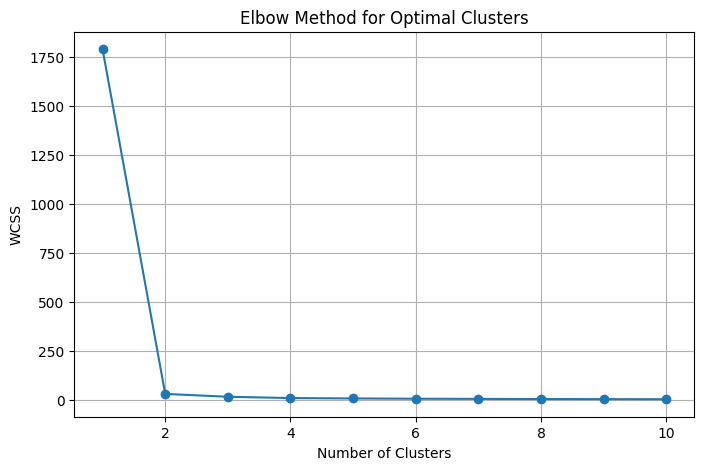

In [ ]:
# Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [ ]:
# Apply K-Means with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

cluster_df['Cluster'] = kmeans.fit_predict(scaled_data)

print("K-Means clustering completed!")
print("\nCluster Distribution:")
print(cluster_df['Cluster'].value_counts().sort_index())

K-Means clustering completed!

Cluster Distribution:
Cluster
0    198
1      1
Name: count, dtype: int64


In [ ]:
# Identify the ward in Cluster 1
outlier_index = cluster_df[cluster_df['Cluster'] == 1].index

print("Unusual Ward Details:")
print(df.loc[outlier_index, ['Ward_No', 'Ward Name'] + features])

print("\nCluster-wise Average:")
print(cluster_df.groupby('Cluster')[features].mean().round(2))

Unusual Ward Details:
     Ward_No Ward Name Population (2011)  Area (sq km)  Lakes # Parks #  \
198      NaN     Total         84,43,675        709.49      192   2,377   

     Playgrounds #  Govt Schools #  Police Stations #  Fire stations #  \
198            390             684                103               12   

     BMTC TTMC #  
198           27  

Cluster-wise Average:
         Population (2011)  Area (sq km)  Lakes #  Parks #  Playgrounds #  \
Cluster                                                                     
0                 42644.82          3.58     0.97    12.01           1.97   
1               8443675.00        709.49   192.00  2377.00         390.00   

         Govt Schools #  Police Stations #  Fire stations #  BMTC TTMC #  
Cluster                                                                   
0                  3.45               0.52             0.06         0.14  
1                684.00             103.00            12.00        27.00  


In [ ]:
# Remove the summary/total row
df = df[df['Ward Name'] != 'Total'].copy()

print("Updated Dataset Shape:", df.shape)
print(df.tail(3))

Updated Dataset Shape: (198, 29)
     Ward_No    Ward Name  BBMP Zone Name Assembly Constituency Name  \
195    196.0   Anjanapura    Bommanahalli            Bangalore South   
196    197.0  Vasanthpura    Bommanahalli            Bangalore South   
197    198.0  Hemmigepura  Rajarajeshwari               Yeshwantpura   

     MP Constituency Population (2011)  Area (sq km)  \
195  Bangalore South             45608          11.4   
196  Bangalore South             62057           5.7   
197  Bangalore North             50440          30.5   

    Households # (Census 2011) Road Length (kms)  Lakes #  ... BMTC TTMC #  \
195                      11049               234        3  ...           0   
196                      16079               143        5  ...           0   
197                      12687               453       10  ...           1   

    Streetlights # Police stn    BBMP Division BBMP Sub Division  \
195           3771        NaN  Bengaluru South        Kottanooru   
196 

In [ ]:
# Select the 9 clustering features again
cluster_df = df[features].copy()

# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_df)

print("Clean data standardization completed!")
print("Dataset shape:", cluster_df.shape)
print("Scaled data shape:", scaled_data.shape)

Clean data standardization completed!
Dataset shape: (198, 9)
Scaled data shape: (198, 9)


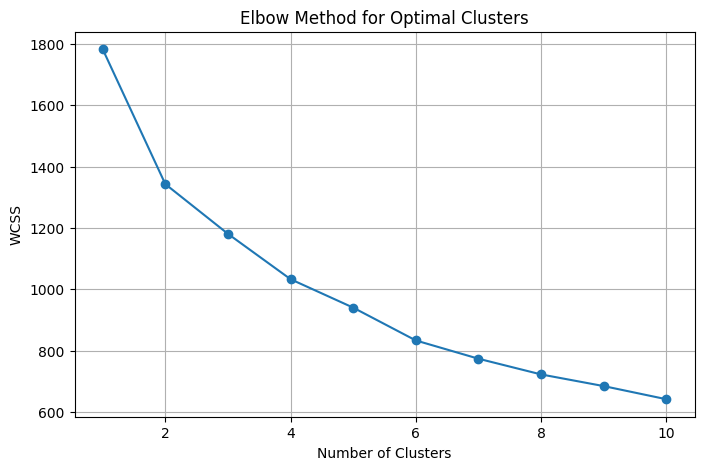

In [ ]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)
    silhouette_scores.append(score)

print("Silhouette Scores:")

for k, score in zip(range(2, 9), silhouette_scores):
    print(f"{k} Clusters: {score:.4f}")

Silhouette Scores:
2 Clusters: 0.4353
3 Clusters: 0.4410
4 Clusters: 0.3670
5 Clusters: 0.3697
6 Clusters: 0.2153
7 Clusters: 0.2042
8 Clusters: 0.2058


In [ ]:
# Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

cluster_df['Cluster'] = kmeans.fit_predict(scaled_data)

print("K-Means clustering completed!")

print("\nCluster Distribution:")
print(cluster_df['Cluster'].value_counts().sort_index())

K-Means clustering completed!

Cluster Distribution:
Cluster
0    166
1     11
2     21
Name: count, dtype: int64


In [ ]:
# Convert all selected features into numeric values
for col in features:
    cluster_df[col] = pd.to_numeric(
        cluster_df[col].astype(str).str.replace(',', '', regex=False),
        errors='coerce'
    )

# Check data types
print("Updated Data Types:")
print(cluster_df[features].dtypes)

# Calculate cluster averages
cluster_summary = cluster_df.groupby('Cluster')[features].mean().round(2)

print("\nCluster-wise Average Facilities:")
print(cluster_summary)

Updated Data Types:
Population (2011)      int64
Area (sq km)         float64
Lakes #                int64
Parks #                int64
Playgrounds #          int64
Govt Schools #         int64
Police Stations #      int64
Fire stations #        int64
BMTC TTMC #            int64
dtype: object

Cluster-wise Average Facilities:
         Population (2011)  Area (sq km)  Lakes #  Parks #  Playgrounds #  \
Cluster                                                                     
0                 40216.01          2.21     0.48     8.82           1.67   
1                 39738.18          4.33     0.73    12.27           2.64   
2                 63366.57         14.03     5.00    37.05           3.95   

         Govt Schools #  Police Stations #  Fire stations #  BMTC TTMC #  
Cluster                                                                   
0                  3.08               0.49             0.00         0.11  
1                  4.09               0.45             1.00 

In [ ]:
# Add cluster labels to the original dataset
df['Cluster'] = cluster_df['Cluster']

# Display ward names grouped by cluster
for cluster in sorted(df['Cluster'].unique()):
    print(f"\nCluster {cluster} Wards:")
    print(df[df['Cluster'] == cluster][['Ward_No', 'Ward Name']].to_string(index=False))


Cluster 0 Wards:
 Ward_No                 Ward Name
     1.0           Kempegowda Ward
     2.0          Chowdeswari Ward
     4.0  Yelahanka Satellite Town
     8.0               Kodigehalli
    10.0         Dodda Bommasandra
    11.0             Kuvempu Nagar
    12.0               Shettihalli
    13.0               Mallasandra
    14.0               Bagalakunte
    15.0             T Dasarahalli
    16.0                 Jalahalli
    17.0                  J P Park
    18.0  Radhakrishna Temple Ward
    19.0             Sanjaya Nagar
    20.0               Ganga Nagar
    21.0                   Hebbala
    22.0    Vishwanath Nagenahalli
    23.0                  Nagavara
    24.0                HBR Layout
    26.0          Ramamurthy Nagar
    28.0              Kammanahalli
    29.0           Kacharkanahalli
    30.0          Kadugondanahalli
    31.0              Kushal Nagar
    32.0         Kaval Bairasandra
    33.0          Manorayana Palya
    34.0              Gangenahalli
  

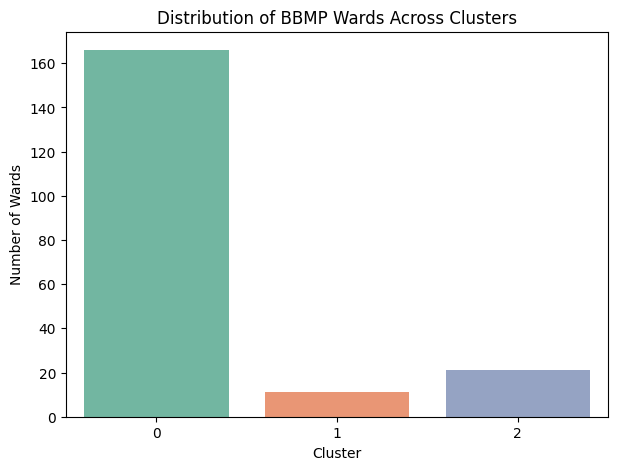

In [ ]:
# Visualize cluster distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x='Cluster',
    data=cluster_df,
    hue='Cluster',
    palette='Set2',
    legend=False
)

plt.title('Distribution of BBMP Wards Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Wards')
plt.show()

In [ ]:
print("Cluster-wise Average Facilities:")
print(cluster_df.groupby('Cluster')[features].mean().round(2))

Cluster-wise Average Facilities:
         Population (2011)  Area (sq km)  Lakes #  Parks #  Playgrounds #  \
Cluster                                                                     
0                 40216.01          2.21     0.48     8.82           1.67   
1                 39738.18          4.33     0.73    12.27           2.64   
2                 63366.57         14.03     5.00    37.05           3.95   

         Govt Schools #  Police Stations #  Fire stations #  BMTC TTMC #  
Cluster                                                                   
0                  3.08               0.49             0.00         0.11  
1                  4.09               0.45             1.00         0.09  
2                  6.10               0.81             0.05         0.38  


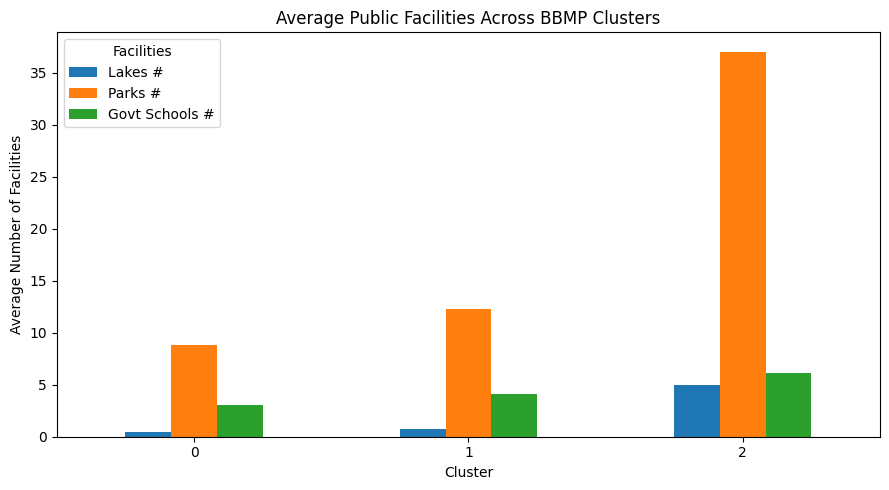

In [ ]:
facility_data = cluster_summary[
    ['Lakes #', 'Parks #', 'Govt Schools #']
]

facility_data.plot(kind='bar', figsize=(9, 5))

plt.title('Average Public Facilities Across BBMP Clusters')
plt.xlabel('Cluster')
plt.ylabel('Average Number of Facilities')
plt.xticks(rotation=0)
plt.legend(title='Facilities')
plt.tight_layout()
plt.show()

In [ ]:
# Save final clustering results
df.to_csv('BBMP_Ward_Clustering_Results.csv', index=False)

print("Clustering results saved successfully!")
print("Total wards:", len(df))
print("Total clusters:", df['Cluster'].nunique())

Clustering results saved successfully!
Total wards: 198
Total clusters: 3


In [5]:
from google.colab import files

files.download('BBMP_Ward_Clustering_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 2: Bengaluru Monsoon Rainfall Forecasting

In [6]:
import pandas as pd

rain_df = pd.read_csv('day -19 2nd dataset.csv')

print("Dataset Shape:", rain_df.shape)
print("\nFirst 5 Rows:")
display(rain_df.head())

print("\nMissing Values:")
print(rain_df.isnull().sum())

Dataset Shape: (127, 16)

First 5 Rows:


,Year,Jan,Feb,Mar,Apr,May,June,July,Aug,Sept,Oct,Nov,Dec,Total,El NiNo (Y/N),La Nina (Y/N)
0,1901,0.0,78.9,0.0,24.3,146.0,47.7,71.6,71.6,318.5,120.3,37.3,23.1,939.3,Y,N
1,1902,0.7,0.0,17.0,58.1,197.8,62.2,32.0,79.5,213.6,219.9,11.1,25.4,917.3,N,N
2,1903,0.0,0.0,0.0,1.5,63.7,109.2,27.9,189.7,475.2,171.1,233.6,29.4,1301.3,Y,N
3,1904,0.5,0.0,0.0,14.4,241.5,49.5,149.3,53.8,126.4,157.2,0.0,1.7,794.3,N,Y
4,1905,1.7,0.0,56.6,32.7,90.6,60.7,58.9,266.4,62.4,227.8,29.2,3.0,890.0,N,N



Missing Values:
Year             0
Jan              0
Feb              0
Mar              0
Apr              0
May              0
June             0
July             0
Aug              0
Sept             0
Oct              0
Nov              0
Dec              1
Total            0
El NiNo (Y/N)    2
La Nina (Y/N)    2
dtype: int64


In [7]:
rain_df['Dec'] = rain_df['Dec'].fillna(rain_df['Dec'].mean())

print("Missing values after cleaning:")
print(rain_df.isnull().sum())

print("\nDataset Shape:", rain_df.shape)

Missing values after cleaning:
Year             0
Jan              0
Feb              0
Mar              0
Apr              0
May              0
June             0
July             0
Aug              0
Sept             0
Oct              0
Nov              0
Dec              0
Total            0
El NiNo (Y/N)    2
La Nina (Y/N)    2
dtype: int64

Dataset Shape: (127, 16)


In [9]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


In [10]:
rain_df['Moving_Average'] = rain_df['Total'].rolling(window=3).mean()

print(rain_df[['Year', 'Total', 'Moving_Average']].head(10))

   Year   Total  Moving_Average
0  1901   939.3             NaN
1  1902   917.3             NaN
2  1903  1301.3     1052.633333
3  1904   794.3     1004.300000
4  1905   890.0      995.200000
5  1906  1011.7      898.666667
6  1907   801.4      901.033333
7  1908   654.8      822.633333
8  1909  1006.0      820.733333
9  1910  1169.9      943.566667


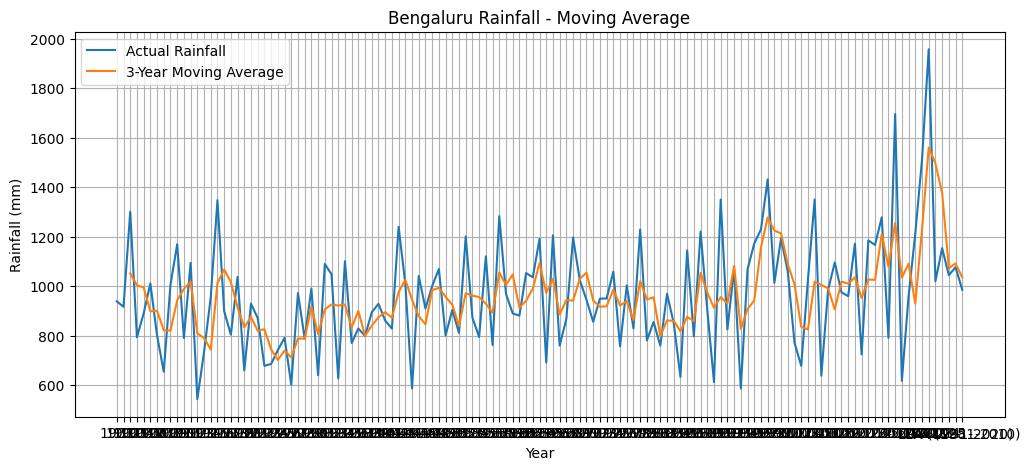

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(rain_df['Year'], rain_df['Total'], label='Actual Rainfall')
plt.plot(rain_df['Year'], rain_df['Moving_Average'], label='3-Year Moving Average')

plt.title('Bengaluru Rainfall - Moving Average')
plt.xlabel('Year')
plt.ylabel('Rainfall (mm)')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

model = SimpleExpSmoothing(
    rain_df['Total'],
    initialization_method='estimated'
)

fit = model.fit(
    smoothing_level=0.3,
    optimized=False
)

rain_df['Exponential_Smoothing'] = fit.fittedvalues

print(rain_df[['Year', 'Total', 'Exponential_Smoothing']].head(10))

   Year   Total  Exponential_Smoothing
0  1901   939.3             961.706667
1  1902   917.3             954.984667
2  1903  1301.3             943.679267
3  1904   794.3            1050.965487
4  1905   890.0             973.965841
5  1906  1011.7             948.776088
6  1907   801.4             967.653262
7  1908   654.8             917.777283
8  1909  1006.0             838.884098
9  1910  1169.9             889.018869


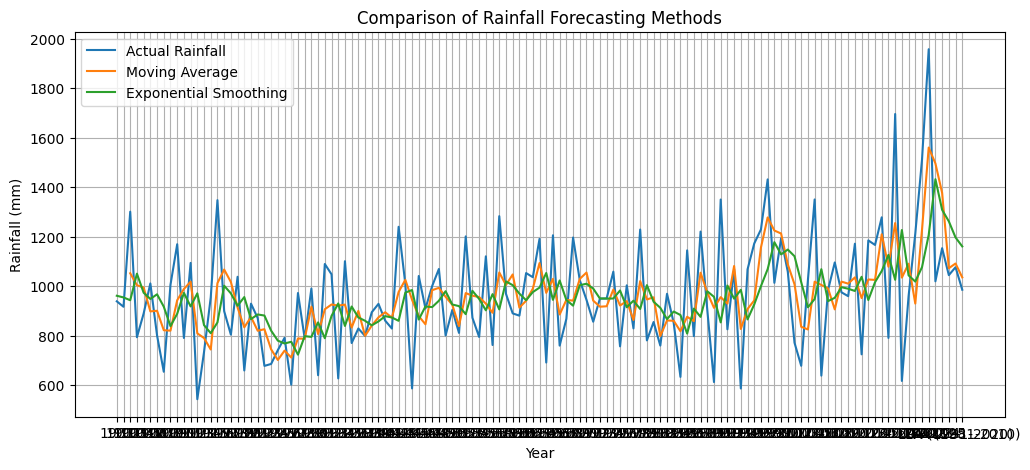

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(rain_df['Year'], rain_df['Total'], label='Actual Rainfall')
plt.plot(rain_df['Year'], rain_df['Moving_Average'], label='Moving Average')
plt.plot(rain_df['Year'], rain_df['Exponential_Smoothing'], label='Exponential Smoothing')

plt.title('Comparison of Rainfall Forecasting Methods')
plt.xlabel('Year')
plt.ylabel('Rainfall (mm)')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Moving Average Forecast
ma_forecast = rain_df['Total'].tail(3).mean()

# Exponential Smoothing Forecast
es_forecast = fit.forecast(1).iloc[0]

print("Next Year Moving Average Forecast:", round(ma_forecast, 2), "mm")
print("Next Year Exponential Smoothing Forecast:", round(es_forecast, 2), "mm")

Next Year Moving Average Forecast: 1036.07 mm
Next Year Exponential Smoothing Forecast: 1108.62 mm


In [17]:
# Keep only valid year records
rain_df['Year'] = pd.to_numeric(rain_df['Year'], errors='coerce')
rain_df = rain_df.dropna(subset=['Year', 'Total']).copy()

rain_df['Year'] = rain_df['Year'].astype(int)
rain_df = rain_df.sort_values('Year').reset_index(drop=True)

# Recalculate Moving Average
rain_df['Moving_Average'] = rain_df['Total'].rolling(window=3).mean()

# Recalculate Exponential Smoothing
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

model = SimpleExpSmoothing(
    rain_df['Total'],
    initialization_method='estimated'
)
fit = model.fit(smoothing_level=0.3, optimized=False)

rain_df['Exponential_Smoothing'] = fit.fittedvalues

# Calculate fresh forecasts
ma_forecast = rain_df['Total'].tail(3).mean()
es_forecast = fit.forecast(1).iloc[0]

next_year = rain_df['Year'].max() + 1

forecast_df = pd.DataFrame({
    'Year': [next_year],
    'Moving_Average_Forecast': [ma_forecast],
    'Exponential_Smoothing_Forecast': [es_forecast]
})

print("Cleaned dataset shape:", rain_df.shape)
display(forecast_df.round(2))

Cleaned dataset shape: (125, 18)


,Year,Moving_Average_Forecast,Exponential_Smoothing_Forecast
0,2026,1073.07,1197.14


In [18]:
# Calculate June to September rainfall
rain_df['Monsoon_Rainfall'] = (
    rain_df['June'] +
    rain_df['July'] +
    rain_df['Aug'] +
    rain_df['Sept']
)

# Calculate 3-year Moving Average
rain_df['Monsoon_MA'] = rain_df['Monsoon_Rainfall'].rolling(window=3).mean()

# Apply Exponential Smoothing
monsoon_model = SimpleExpSmoothing(
    rain_df['Monsoon_Rainfall'],
    initialization_method='estimated'
)

monsoon_fit = monsoon_model.fit(
    smoothing_level=0.3,
    optimized=False
)

# Forecast 2026
monsoon_ma_forecast = rain_df['Monsoon_Rainfall'].tail(3).mean()
monsoon_es_forecast = monsoon_fit.forecast(1).iloc[0]

print("2026 Monsoon Rainfall Forecast")
print("Moving Average:", round(monsoon_ma_forecast, 2), "mm")
print("Exponential Smoothing:", round(monsoon_es_forecast, 2), "mm")

2026 Monsoon Rainfall Forecast
Moving Average: 525.23 mm
Exponential Smoothing: 604.6 mm


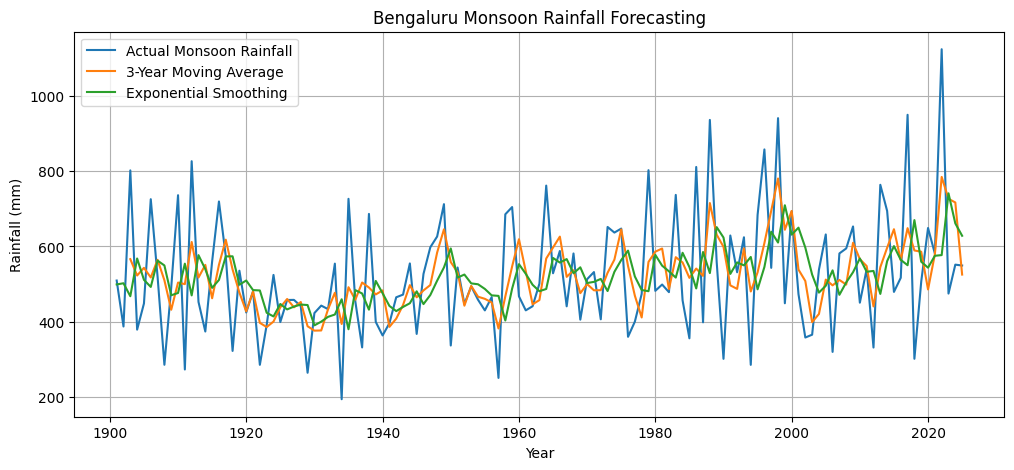

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(rain_df['Year'], rain_df['Monsoon_Rainfall'],
         label='Actual Monsoon Rainfall')

plt.plot(rain_df['Year'], rain_df['Monsoon_MA'],
         label='3-Year Moving Average')

plt.plot(rain_df['Year'], monsoon_fit.fittedvalues,
         label='Exponential Smoothing')

plt.title('Bengaluru Monsoon Rainfall Forecasting')
plt.xlabel('Year')
plt.ylabel('Rainfall (mm)')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# Create final forecasting results
final_forecast = pd.DataFrame({
    'Year': [2026],
    'Moving_Average_Forecast_mm': [monsoon_ma_forecast],
    'Exponential_Smoothing_Forecast_mm': [monsoon_es_forecast]
})

# Save CSV
final_forecast.to_csv('Bengaluru_Monsoon_Forecast_Results.csv', index=False)

print("Forecast results saved successfully!")
display(final_forecast.round(2))

Forecast results saved successfully!


,Year,Moving_Average_Forecast_mm,Exponential_Smoothing_Forecast_mm
0,2026,525.23,604.6


In [21]:
from google.colab import files
files.download('Bengaluru_Monsoon_Forecast_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>